In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr, kendalltau
from scipy.cluster.hierarchy import linkage, dendrogram

In [2]:
df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

df.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [3]:
df.shape

(23486, 11)

In [4]:
df.columns.tolist()

['Unnamed: 0',
 'Clothing ID',
 'Age',
 'Title',
 'Review Text',
 'Rating',
 'Recommended IND',
 'Positive Feedback Count',
 'Division Name',
 'Department Name',
 'Class Name']

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB


In [6]:
numerical_cols = [
    "Age",
    "Rating",
    "Recommended IND",
    "Positive Feedback Count"
]

num_df = df[numerical_cols].copy()

num_df.head()

,Age,Rating,Recommended IND,Positive Feedback Count
0,33,4,1,0
1,34,5,1,4
2,60,3,0,0
3,50,5,1,0
4,47,5,1,6


Calculate Pearson correlation

In [7]:
pearson_corr = num_df.corr(method="pearson")

print("Pearson Correlation:")
display(pearson_corr)

Pearson Correlation:


,Age,Rating,Recommended IND,Positive Feedback Count
Age,1.000000,0.026831,0.030622,0.043079
Rating,0.026831,1.000000,0.792336,-0.064961
Recommended IND,0.030622,0.792336,1.000000,-0.069045
Positive Feedback Count,0.043079,-0.064961,-0.069045,1.000000


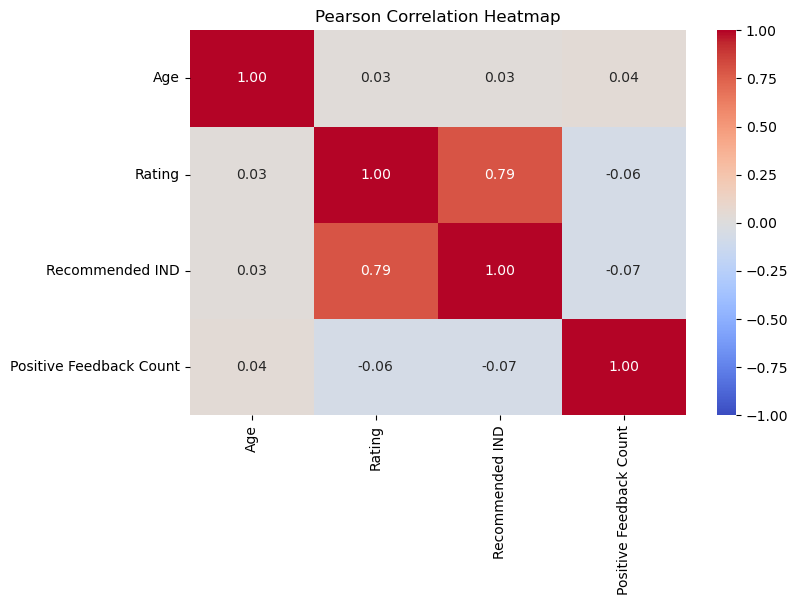

In [8]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Pearson Correlation Heatmap")
plt.show()

Calculate Spearman correlation

In [9]:
spearman_corr = num_df.corr(method="spearman")

print("Spearman Correlation:")
display(spearman_corr)

Spearman Correlation:


,Age,Rating,Recommended IND,Positive Feedback Count
Age,1.000000,0.031082,0.031032,0.075583
Rating,0.031082,1.000000,0.693509,-0.068327
Recommended IND,0.031032,0.693509,1.000000,-0.080864
Positive Feedback Count,0.075583,-0.068327,-0.080864,1.000000


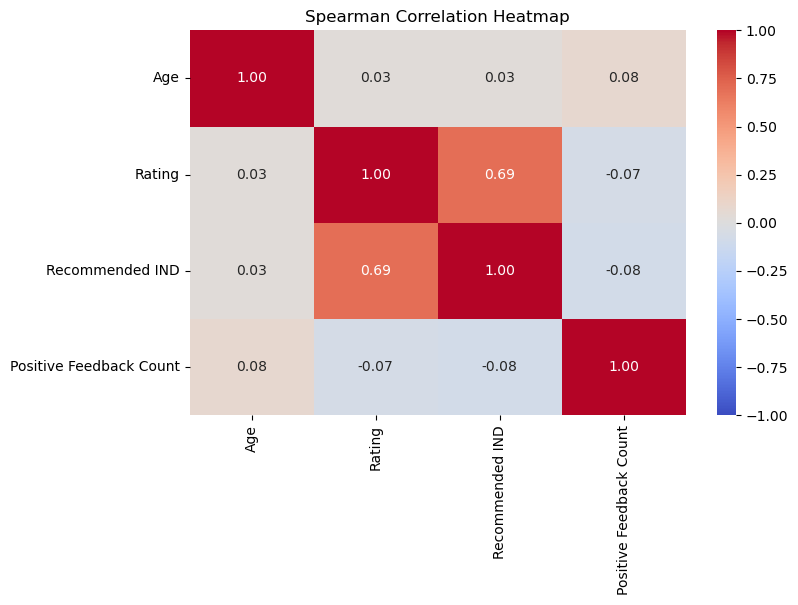

In [10]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Spearman Correlation Heatmap")
plt.show()

Calculate Kendall correlation

In [11]:
kendall_corr = num_df.corr(method="kendall")

print("Kendall Correlation:")
display(kendall_corr)

Kendall Correlation:


,Age,Rating,Recommended IND,Positive Feedback Count
Age,1.000000,0.024080,0.025643,0.056110
Rating,0.024080,1.000000,0.648398,-0.057526
Recommended IND,0.025643,0.648398,1.000000,-0.072850
Positive Feedback Count,0.056110,-0.057526,-0.072850,1.000000


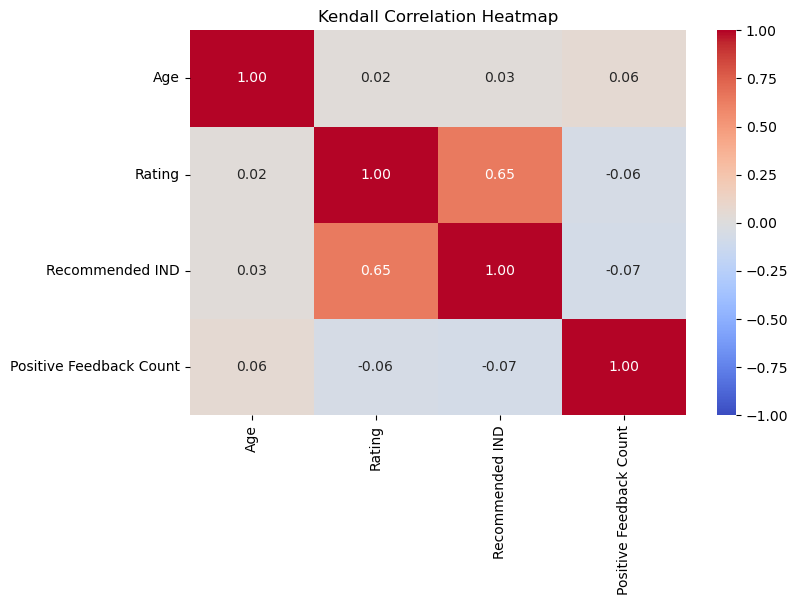

In [12]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    kendall_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Kendall Correlation Heatmap")
plt.show()

Dynamically filter significant correlations

In [13]:
methods = {
    "Pearson": pearsonr,
    "Spearman": spearmanr,
    "Kendall": kendalltau
}

results = []

for method_name, method_func in methods.items():

    for i in range(len(numerical_cols)):
        for j in range(i + 1, len(numerical_cols)):

            col1 = numerical_cols[i]
            col2 = numerical_cols[j]

            temp = num_df[[col1, col2]].dropna()

            corr, p_value = method_func(
                temp[col1],
                temp[col2]
            )

            results.append({
                "Method": method_name,
                "Variable 1": col1,
                "Variable 2": col2,
                "Correlation": corr,
                "P-value": p_value
            })

results_df = pd.DataFrame(results)

results_df["Significant"] = results_df["P-value"] < 0.05

significant_corr = results_df[
    (results_df["P-value"] < 0.05) &
    (results_df["Correlation"].abs() >= 0.10)
].sort_values("P-value")

display(significant_corr.round(4))

,Method,Variable 1,Variable 2,Correlation,P-value,Significant
3,Pearson,Rating,Recommended IND,0.7923,0.0,True
9,Spearman,Rating,Recommended IND,0.6935,0.0,True
15,Kendall,Rating,Recommended IND,0.6484,0.0,True


Create a hierarchical clustering heatmap

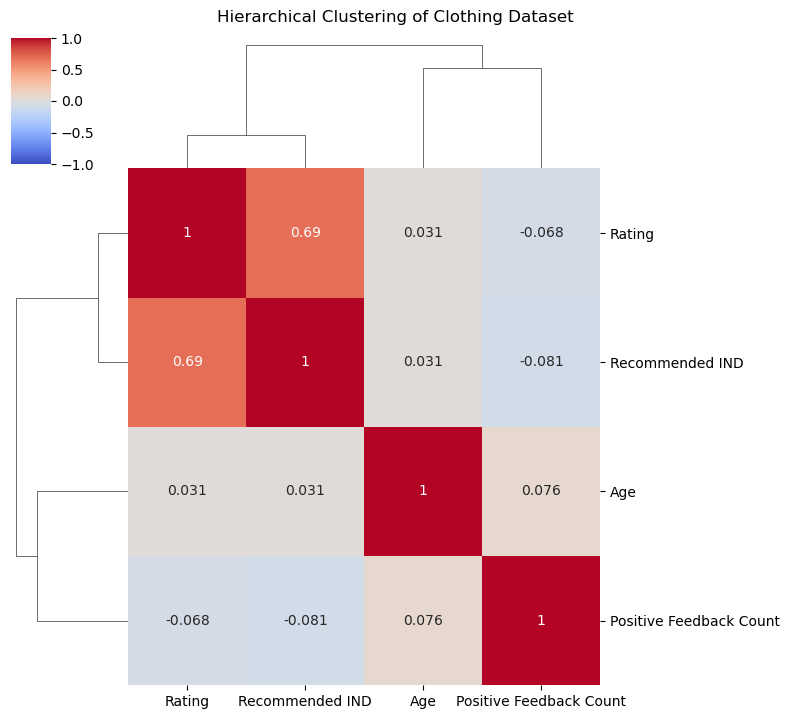

In [14]:
sns.clustermap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    figsize=(8, 7),
    method="average"
)

plt.suptitle(
    "Hierarchical Clustering of Clothing Dataset",
    y=1.02
)

plt.show()

Compare all three methods

In [15]:
comparison = results_df.pivot_table(
    index=["Variable 1", "Variable 2"],
    columns="Method",
    values="Correlation"
)

print("Correlation Comparison:")
display(comparison.round(3))

Correlation Comparison:


Method                                   Kendall  Pearson  Spearman
Variable 1      Variable 2                                         
Age             Positive Feedback Count    0.056    0.043     0.076
                Rating                     0.024    0.027     0.031
                Recommended IND            0.026    0.031     0.031
Rating          Positive Feedback Count   -0.058   -0.065    -0.068
                Recommended IND            0.648    0.792     0.694
Recommended IND Positive Feedback Count   -0.073   -0.069    -0.081

Automatically identify the strongest correlations

In [16]:
strongest = results_df.loc[
    results_df["Correlation"].abs().idxmax()
]

print("Strongest Correlation:")
print("Method:", strongest["Method"])
print("Variable 1:", strongest["Variable 1"])
print("Variable 2:", strongest["Variable 2"])
print("Correlation:", round(strongest["Correlation"], 3))
print("P-value:", round(strongest["P-value"], 5))

Strongest Correlation:
Method: Pearson
Variable 1: Rating
Variable 2: Recommended IND
Correlation: 0.792
P-value: 0.0


In [17]:
if not significant_corr.empty:
    print("Strongest Significant Correlation:")
    display(significant_corr.head(1).round(4))
else:
    print("No correlations passed the selected thresholds.")

Strongest Significant Correlation:


,Method,Variable 1,Variable 2,Correlation,P-value,Significant
3,Pearson,Rating,Recommended IND,0.7923,0.0,True
